In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

folder="/content/drive/MyDrive/SNN_XAI_PROJECT"

print("Project folder:",folder)
print("Files:",os.listdir(folder))

Mounted at /content/drive
Project folder: /content/drive/MyDrive/SNN_XAI_PROJECT
Files: ['MILK10k_Training_GroundTruth.csv', 'MILK10k_Training_Input.zip', 'MILK10k_Training_Supplement.csv', 'MILK10k_Training_Metadata.csv', 'images', 'MILK10k_Class_Distribution.png', 'checkpoints', 'checkpoints_class_balanced', 'checkpoints_v6']


In [ ]:
import pandas as pd

df=pd.read_csv(os.path.join(folder,"MILK10k_Training_GroundTruth.csv"))
metadata=pd.read_csv(os.path.join(folder,"MILK10k_Training_Metadata.csv"))
supplement=pd.read_csv(os.path.join(folder,"MILK10k_Training_Supplement.csv"))

image_root=os.path.join(folder,"images","MILK10k_Training_Input")

print("Ground Truth:",df.shape)
print("Metadata:",metadata.shape)
print("Supplement:",supplement.shape)
print("Images folder exists:",os.path.exists(image_root))

Ground Truth: (5240, 12)
Metadata: (10480, 17)
Supplement: (10480, 4)
Images folder exists: True


In [ ]:
from PIL import Image

for image_type in metadata["image_type"].unique():
    row=metadata[metadata["image_type"]==image_type].iloc[0]
    path=os.path.join(image_root,row["lesion_id"],row["isic_id"]+".jpg")
    with Image.open(path) as img:
        print(image_type,":",img.size)

clinical: close-up : (600, 450)
dermoscopic : (600, 450)


In [ ]:
import numpy as np

class_names=["AKIEC","BCC","BEN_OTH","BKL","DF","INF","MAL_OTH","MEL","NV","SCCKA","VASC"]

all_labels=df[class_names].to_numpy().argmax(axis=1)

print("Total lesions:",len(df))
print("Total classes:",len(class_names))
print("Class distribution:")
print(df[class_names].sum())

Total lesions: 5240
Total classes: 11
Class distribution:
AKIEC       303.0
BCC        2522.0
BEN_OTH      44.0
BKL         544.0
DF           52.0
INF          50.0
MAL_OTH       9.0
MEL         450.0
NV          746.0
SCCKA       473.0
VASC         47.0
dtype: float64


Ground Truth:


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,IL_0003176,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,IL_0004688,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,IL_0005081,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,IL_0006177,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Extracted image folders: 5242
Image type: clinical: close-up
Image size: (600, 450)


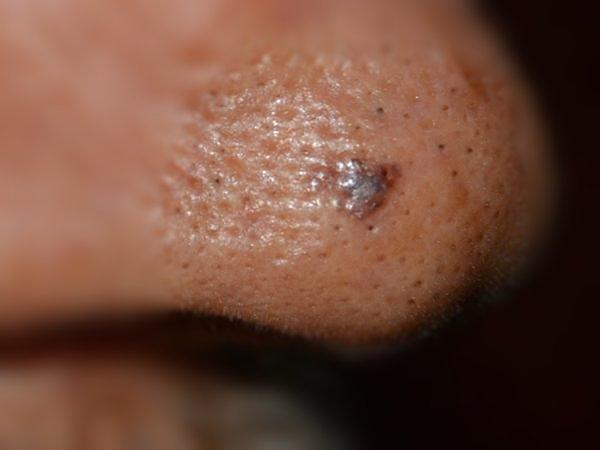

In [ ]:
print("Ground Truth:")
display(df.head())

print("Extracted image folders:",len(os.listdir(image_root)))

row=metadata.iloc[0]
image_path=os.path.join(image_root,row["lesion_id"],row["isic_id"]+".jpg")

img=Image.open(image_path)
print("Image type:",row["image_type"])
print("Image size:",img.size)
display(img)

In [ ]:
from torchvision import transforms

train_transform=transforms.Compose([
    transforms.Resize((144,192)),
    transforms.Pad((0,24,0,24)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15,contrast=0.15,saturation=0.10),
    transforms.ToTensor()
])

eval_transform=transforms.Compose([
    transforms.Resize((144,192)),
    transforms.Pad((0,24,0,24)),
    transforms.ToTensor()
])

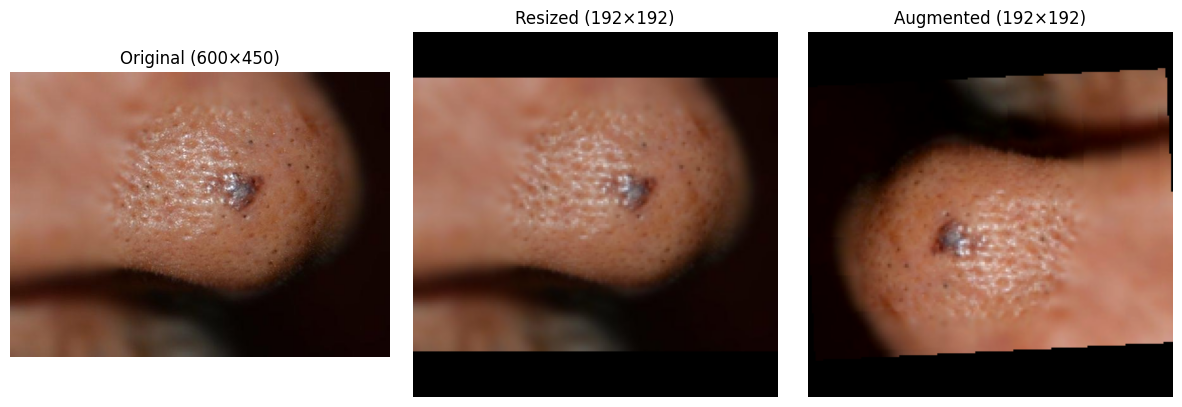

In [ ]:
import matplotlib.pyplot as plt
from torchvision.transforms.functional import to_pil_image

original=Image.open(image_path).convert("RGB")
resized=eval_transform(original)
augmented=train_transform(original)

fig,axes=plt.subplots(1,3,figsize=(12,4))

axes[0].imshow(original)
axes[0].set_title("Original (600×450)")

axes[1].imshow(to_pil_image(resized))
axes[1].set_title("Resized (192×192)")

axes[2].imshow(to_pil_image(augmented))
axes[2].set_title("Augmented (192×192)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

indices=np.arange(len(df))

train_idx,temp_idx=train_test_split(
    indices,test_size=0.30,stratify=all_labels,random_state=42
)

val_idx,test_idx=train_test_split(
    temp_idx,test_size=0.50,stratify=all_labels[temp_idx],random_state=42
)

print("Training:",len(train_idx))
print("Validation:",len(val_idx))
print("Testing:",len(test_idx))

Training: 3668
Validation: 786
Testing: 786


In [ ]:
import torch
from torch.utils.data import Dataset

class MILK10kDataset(Dataset):
    def __init__(self,df,metadata,image_root,transform):
        self.df=df.reset_index(drop=True)
        self.image_root=image_root
        self.transform=transform
        self.image_pairs=metadata.pivot(
            index="lesion_id",
            columns="image_type",
            values="isic_id"
        ).loc[self.df["lesion_id"]]

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):
        row=self.df.iloc[idx]
        lesion_id=row["lesion_id"]

        derm_id=self.image_pairs.iloc[idx]["dermoscopic"]
        close_id=self.image_pairs.iloc[idx]["clinical: close-up"]

        derm_path=os.path.join(self.image_root,lesion_id,derm_id+".jpg")
        close_path=os.path.join(self.image_root,lesion_id,close_id+".jpg")

        with Image.open(derm_path) as img:
            derm=self.transform(img.convert("RGB"))

        with Image.open(close_path) as img:
            close=self.transform(img.convert("RGB"))

        label=int(all_labels[idx])

        return derm,close,label

In [ ]:
from torch.utils.data import DataLoader,WeightedRandomSampler

train_labels=all_labels[train_idx]
class_counts=np.bincount(train_labels,minlength=len(class_names))
class_weights=1.0/np.sqrt(class_counts)
sample_weights=class_weights[train_labels]

sampler=WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights,dtype=torch.double),
    num_samples=len(train_idx),
    replacement=True
)

train_loader=DataLoader(train_dataset,batch_size=8,sampler=sampler,num_workers=0)
val_loader=DataLoader(val_dataset,batch_size=8,shuffle=False,num_workers=0)
test_loader=DataLoader(test_dataset,batch_size=8,shuffle=False,num_workers=0)

print("Training batches:",len(train_loader))
print("Validation batches:",len(val_loader))
print("Testing batches:",len(test_loader))

Training batches: 459
Validation batches: 99
Testing batches: 99


In [ ]:
import importlib.util

if importlib.util.find_spec("snntorch") is None:
    %pip install snntorch
import torch.nn as nn
import snntorch as snn
from snntorch import surrogate,utils

class SpikingConvBlock(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__()
        self.conv=nn.Conv2d(in_channels,out_channels,kernel_size=3,padding=1)
        self.bn=nn.BatchNorm2d(out_channels)
        self.if_neuron=snn.Leaky(beta=1.0,threshold=0.5,spike_grad=surrogate.fast_sigmoid(slope=5))

    def forward(self,x,mem):
        current=self.bn(self.conv(x))
        spikes,mem=self.if_neuron(current,mem)
        return spikes,mem

class SNNBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.blocks=nn.ModuleList([
            SpikingConvBlock(3,32),
            SpikingConvBlock(32,64),
            SpikingConvBlock(64,128)
        ])
        self.pool=nn.AvgPool2d(2)
        self.global_pool=nn.AdaptiveAvgPool2d(1)

    def forward(self,x,mem_states=None):
        if mem_states is None:
            mem_states=[None]*len(self.blocks)
        new_mem_states=[]
        for block,mem in zip(self.blocks,mem_states):
            x,mem=block(x,mem)
            x=self.pool(x)
            new_mem_states.append(mem)
        features=self.global_pool(x)
        features=torch.flatten(features,1)
        return features,new_mem_states

class DualBranchSNN(nn.Module):
    def __init__(self,num_classes=11,num_steps=8):
        super().__init__()
        self.num_steps=num_steps
        self.derm_branch=SNNBranch()
        self.close_branch=SNNBranch()
        self.fc1=nn.Linear(256,128)
        self.fc1_if=snn.Leaky(beta=1.0,threshold=0.5,spike_grad=surrogate.fast_sigmoid(slope=5))
        self.fc2=nn.Linear(128,num_classes)

    def forward(self,derm,close):
        utils.reset(self)
        derm_mem=None
        close_mem=None
        fc_mem=None
        output=0

        for t in range(self.num_steps):
            derm_spikes=torch.bernoulli(derm)
            close_spikes=torch.bernoulli(close)

            derm_features,derm_mem=self.derm_branch(derm_spikes,derm_mem)
            close_features,close_mem=self.close_branch(close_spikes,close_mem)

            combined=torch.cat((derm_features,close_features),dim=1)
            fc_current=self.fc1(combined)
            fc_spikes,fc_mem=self.fc1_if(fc_current,fc_mem)
            output=output+self.fc2(fc_spikes)

        return output/self.num_steps

In [ ]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

model=DualBranchSNN(num_classes=11,num_steps=8).to(device)

total_params=sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Device:",device)
print("Trainable parameters:",total_params)

Device: cuda
Trainable parameters: 221707


In [ ]:
import torch.optim as optim

criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.0001)

print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.0001")

Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.0001


In [ ]:
checkpoint_dir=os.path.join(folder,"checkpoints_v7_augmentation")
os.makedirs(checkpoint_dir,exist_ok=True)

num_epochs=10
best_f1=-1.0

print("Checkpoint folder:",checkpoint_dir)
print("Training epochs:",num_epochs)
print("Best Macro-F1 initialized:",best_f1)

Checkpoint folder: /content/drive/MyDrive/SNN_XAI_PROJECT/checkpoints_v7_augmentation
Training epochs: 10
Best Macro-F1 initialized: -1.0


In [ ]:
spike_activity={}

def spike_hook(name):
    def hook(module,inputs,outputs):
        spikes=outputs[0]
        spike_activity.setdefault(name,[]).append(spikes.detach().mean().item()*100)
    return hook

hooks=[]

for name,module in model.named_modules():
    if isinstance(module,snn.Leaky):
        hooks.append(module.register_forward_hook(spike_hook(name)))

model.eval()

with torch.no_grad():
    derm,close,labels=next(iter(val_loader))
    outputs=model(derm.to(device),close.to(device))

for hook in hooks:
    hook.remove()

print("Spike Activity Before Training:\n")

for name,values in spike_activity.items():
    print(f"{name}: {np.mean(values):.2f}%")

print("\nOutput shape:",outputs.shape)

Spike Activity Before Training:

derm_branch.blocks.0.if_neuron: 28.40%
derm_branch.blocks.1.if_neuron: 33.42%
derm_branch.blocks.2.if_neuron: 37.30%
close_branch.blocks.0.if_neuron: 31.52%
close_branch.blocks.1.if_neuron: 32.38%
close_branch.blocks.2.if_neuron: 36.40%
fc1_if: 23.58%

Output shape: torch.Size([8, 11])


In [ ]:
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

for epoch in range(num_epochs):
    model.train()
    train_loss=0.0
    train_correct=0
    train_total=0

    for derm,close,labels in tqdm(train_loader,desc=f"Epoch {epoch+1}/{num_epochs}"):
        derm=derm.to(device)
        close=close.to(device)
        labels=labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs=model(derm,close)
        loss=criterion(outputs,labels)
        loss.backward()
        optimizer.step()

        train_loss+=loss.item()*labels.size(0)
        train_correct+=(outputs.argmax(dim=1)==labels).sum().item()
        train_total+=labels.size(0)

    model.eval()
    val_true=[]
    val_pred=[]

    with torch.no_grad():
        for derm,close,labels in val_loader:
            outputs=model(derm.to(device),close.to(device))
            val_true.extend(labels.tolist())
            val_pred.extend(outputs.argmax(dim=1).cpu().tolist())

    epoch_loss=train_loss/train_total
    train_acc=100*train_correct/train_total
    val_acc=100*np.mean(np.array(val_true)==np.array(val_pred))
    val_f1=float(f1_score(
        val_true,val_pred,
        labels=list(range(11)),
        average="macro",
        zero_division=0
    ))

    checkpoint={
        "epoch":epoch+1,
        "model_state_dict":model.state_dict(),
        "optimizer_state_dict":optimizer.state_dict(),
        "train_loss":float(epoch_loss),
        "train_accuracy":float(train_acc),
        "val_accuracy":float(val_acc),
        "val_macro_f1":val_f1
    }

    torch.save(checkpoint,os.path.join(checkpoint_dir,"latest_checkpoint.pth"))

    if val_f1>best_f1:
        best_f1=val_f1
        torch.save(checkpoint,os.path.join(checkpoint_dir,"best_model.pth"))

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {epoch_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val Accuracy: {val_acc:.2f}% | Val Macro-F1: {val_f1:.4f}")
    print(f"Best Macro-F1: {best_f1:.4f}\n")

Epoch 1/10:   0%|          | 0/459 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 2.0169 | Train Accuracy: 30.21%
Val Accuracy: 47.46% | Val Macro-F1: 0.1144
Best Macro-F1: 0.1144



Epoch 2/10:   0%|          | 0/459 [00:00<?, ?it/s]


Epoch 2/10
Train Loss: 1.9175 | Train Accuracy: 34.49%
Val Accuracy: 51.65% | Val Macro-F1: 0.1239
Best Macro-F1: 0.1239



Epoch 3/10:   0%|          | 0/459 [00:00<?, ?it/s]


Epoch 3/10
Train Loss: 1.8850 | Train Accuracy: 33.70%
Val Accuracy: 51.91% | Val Macro-F1: 0.1461
Best Macro-F1: 0.1461



... (7 outputs left out)


Epoch 7/10
Train Loss: 1.7759 | Train Accuracy: 37.00%
Val Accuracy: 54.71% | Val Macro-F1: 0.1506
Best Macro-F1: 0.1599



Epoch 8/10:   0%|          | 0/459 [00:00<?, ?it/s]


Epoch 8/10
Train Loss: 1.7957 | Train Accuracy: 36.15%
Val Accuracy: 53.44% | Val Macro-F1: 0.1490
Best Macro-F1: 0.1599



Epoch 9/10:   0%|          | 0/459 [00:00<?, ?it/s]